# M4 part 1: rest — rest-entry kernels, intrinsic timescales, rest drift

Loads and plots only. Numbers come from `run_rest_kernels.py`: one job per recday (>= 5 trials for the
awake reference), `--merge`, and `--gate` (planted units on the gate recdays' real rest blocks).

Design, after the 2026-10-15 and 2026-10-16 revisions (`rest_kernels.py` docstring; handoff §7):
- **State terms, continuous only.** Deciles of the DOWN-state fraction per 10 s window, with 0 as its own
  bin. No binary SWS flag: the LFP check could not validate staging.
- **Shared state by division.** Each unit's counts are divided by the other half's relative population
  rate (units split even / odd): the median over the half's units >= 0.3 Hz of each unit's 30 s count
  over its own mean. Rest-entry locking is therefore relative to the rest of the population.
- **Rest splits.** Low-DOWN windows (within the awake range) and high-DOWN windows (>= 0.1) replace
  non-SWS / SWS for the timescales and drift.

In [1]:
RUN_MODE = 'load'   # never computes; rerun the sbatch jobs and merges instead
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import event_kernels_plots as P
%matplotlib inline
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
fig = lambda name: os.path.join(P.M4_FIG_DIR, name)
R = {'LEC': P.load_rest('LEC'), 'PFC': P.load_rest('PFC')}
for ds in R:
    print(ds, os.path.basename(R[ds]['_path']))

LEC rest_lec_mt5_np100.pkl
PFC rest_pfc_mt5_np100.pkl


## Gates (full runs; planted units on the gate recdays' real rest blocks)

In [2]:
g = P.table_m4_gates()
g[['dataset', 'gate', 'check', 'value', 'passed', 'must']]

,dataset,gate,check,value,passed,must
0,LEC,G1,proxy at the real unit count: SWS-window AUC,1.000,True,True
1,LEC,G1,the same: SWS recall / quiet wake called SWS /...,1.000 / 0.042 / 154,True,False
2,LEC,G1,"planted population, real calibration: SWS-wind...",1.000 / 1.000 / 0.008,True,False
3,LEC,G2,rest-entry ramps: locked with the state terms,0.833,True,True
4,LEC,G2,rest-entry ramps: Stage 2 tau within 2x,0.8,True,True
5,LEC,G3,SWS-gain units: locked with the state terms (b...,0 of 8 (p 1.000) / 1.000,True,True
6,LEC,G4,noise: locked with the state terms (binomial p...,0 of 54 (p 1.000),True,True
7,LEC,G4,noise: locked without the state terms (reported),24 of 54,True,False
8,LEC,G4b,shared rest-entry ramp in every unit: noise lo...,2 of 54,True,False
9,LEC,G4b,shared rest-entry ramp in every unit: noise lo...,49 of 54,True,False


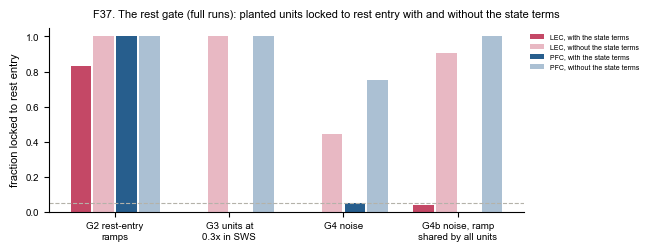

,dataset,world,kind,state_terms,locked,n
0,LEC,planted,rest_ramp,with,0.833,12
1,LEC,planted,sws_gain,with,0.000,8
2,LEC,planted,noise,with,0.000,54
3,LEC,planted,rest_ramp,without,1.000,12
4,LEC,planted,sws_gain,without,1.000,8
5,LEC,planted,noise,without,0.444,54
6,LEC,shared ramp,rest_ramp,with,0.917,12
7,LEC,shared ramp,sws_gain,with,0.125,8
8,LEC,shared ramp,noise,with,0.037,54
9,LEC,shared ramp,rest_ramp,without,0.833,12


In [3]:
P.plot_rest_gates(out_path=fig('F37_rest_gates')); plt.show()
P.table_rest_gate_locking().round(3)

## Recdays: skips, proxy calibration and the units that can divide

In [4]:
pd.concat({ds: m['summary'].assign(skipped=m['summary']['skipped'].fillna(''),
                                     stage1_skipped=m['summary']['stage1_skipped'].fillna(''))
           for ds, m in R.items()})

recday mouse                skipped                                     stage1_skipped proxy_usable  power_auc  power_recall  power_quiet   sws_cut  theta  n_blocks  n_units  \
LEC 0   ah08_20250613_20250615  ah08                                                                                   True   1.000000      0.051852     0.000000  0.202520    1.0        10      151   
    1   ah08_20250616_20250617  ah08                                                                                   True   0.977602      0.000000     0.000000  0.264700    0.0        11      164   
    2   ah08_20250618_20250619  ah08                                                                                   True   0.978947      0.000000     0.000000  0.150740    0.0        11      183   
    3   ah08_20250620_20250623  ah08                                                                                   True   0.989534      0.000000     0.000000  0.132940    0.0        11      108   
    4   ah08_20250624_20250625  ah08                                                                                   True   1.000000      0.749141     0.000000  0.179313    2.0        12      186   
    5   ah10_20250613_20250615  ah10                                                                                   True   1.000000      1.000000     0.000000  0.063400    4.0        10      139   
    6   ah10_20250616_20250617  ah10                                                                                   True   1.000000      1.000000     0.041667  0.012595    4.0        11      154   
    7   ah10_20250618_20250619  ah10                                                                                   True   1.000000      1.000000     0.041667  0.020000    5.0        10      162   
    8   ah10_20250620_20250623  ah10                                                                                   True   1.000000      1.000000     0.000000  0.113280    4.0        10      153   
    9   ah10_20250624_20250625  ah10                                                                                   True   0.999965      1.000000     0.041667  0.026440    6.0        12      164   
    10  ly05_20250613_20250615  ly05                                                                                   True   1.000000      1.000000     0.020833  0.087500    2.0        10      117   
    11  ly05_20250616_20250617  ly05                                                                                   True   1.000000      0.432602     0.000000  0.142500    1.0        11      116   
    12  ly05_20250618_20250619  ly05                                                                                   True   1.000000      0.996139     0.000000  0.083970    1.0        10      109   
    13  ly05_20250620_20250623  ly05                                                                                   True   1.000000      0.933884     0.000000  0.113100    1.0        10       91   
    14  ly05_20250624_20250625  ly05                                                                                   True   0.997352      0.017699     0.000000  0.081663    0.0        12       74   
    15  ly06_20250613_20250615  ly06                                                                                  False   0.755418      0.000000     0.000000  0.678450    0.0        10       68   
    16  ly06_20250616_20250617  ly06                                                                                   True   1.000000      0.976667     0.000000  0.120405    2.0        11       79   
    17  ly06_20250618_20250619  ly06                                                                                   True   1.000000      1.000000     0.041667  0.030450    3.0        10       76   
    18  ly06_20250620_20250623  ly06                                                                                   True   1.000000      0.990625     0.000000  0.103745    2.0         9       67   
    

## F31. The DOWN-state proxy against LFP delta (LEC, 2 blocks per mouse)

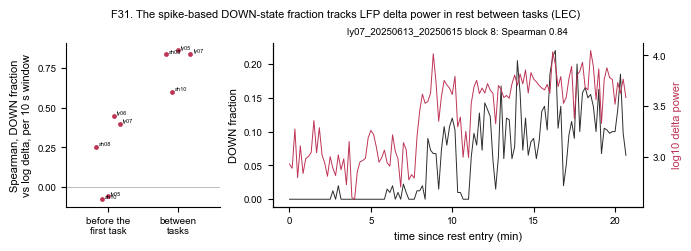

,recday,mouse,block,kind,windows,spearman_log_delta,down_frac_nonzero,hpf_channels,superseded_lfp_sws_frac,superseded_proxy_sws_frac,superseded_auc
0,ah08_20250613_20250615,ah08,5,pre,254,0.253,0.031,0,0.000,0.000,NaN
1,ah08_20250613_20250615,ah08,8,post,125,0.834,0.640,0,0.000,0.000,NaN
2,ah10_20250613_20250615,ah10,5,pre,254,-0.076,0.024,120,0.016,0.000,0.488
3,ah10_20250613_20250615,ah10,7,post,125,0.600,0.472,120,0.000,0.064,NaN
4,ly05_20250613_20250615,ly05,5,pre,254,-0.058,0.031,84,0.000,0.000,NaN
5,ly05_20250613_20250615,ly05,8,post,122,0.858,0.557,84,0.000,0.123,NaN
6,ly06_20250613_20250615,ly06,5,pre,254,0.448,0.094,57,0.000,0.000,NaN
7,ly06_20250613_20250615,ly06,6,post,123,NaN,0.000,57,0.000,0.000,NaN
8,ly07_20250613_20250615,ly07,5,pre,254,0.397,0.134,150,0.000,0.000,NaN
9,ly07_20250613_20250615,ly07,8,post,125,0.837,0.656,150,0.000,0.280,NaN


In [5]:
P.plot_lfp_check(out_path=fig('F31_lfp_check')); plt.show()
pd.read_csv(os.path.join(P.LFP_DIR, 'summary.csv')).round(3)

## F32. Units locked to rest entry, and their overlap with maze entry

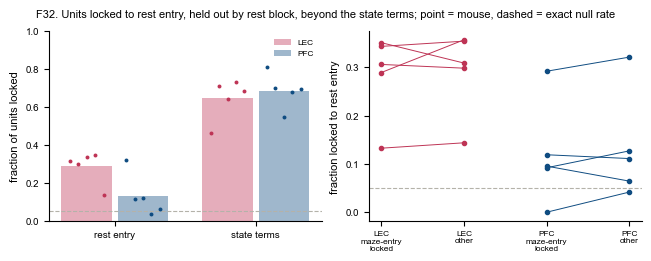

mean    min    max  count
dataset group                                    
LEC     ev_rest_entry  0.289  0.137  0.349      5
        state          0.647  0.463  0.734      5
PFC     ev_rest_entry  0.132  0.036  0.323      5
        state          0.687  0.548  0.811      5

In [6]:
P.plot_rest_locking(R, out_path=fig('F32_rest_locking')); plt.show()
t = P.table_rest_locking(R)
t.groupby(['dataset', 'group'])['fraction'].agg(['mean', 'min', 'max', 'count']).round(3)

In [7]:
o = P.table_rest_vs_maze(R)
o.pivot_table(index=['dataset', 'mouse'], columns='maze_entry_locked', values='p_rest_locked').round(3)

maze_entry_locked  False  True 
dataset mouse                  
LEC     ah08       0.309  0.351
        ah10       0.298  0.306
        ly05       0.357  0.289
        ly06       0.354  0.343
        ly07       0.144  0.132
PFC     ab03       0.321  0.292
        ah04       0.111  0.119
        ah07       0.127  0.092
        me10       0.042  0.000
        me11       0.064  0.095

## F33. Shapes of rest-entry kernels, and tau after rest entry against maze entry

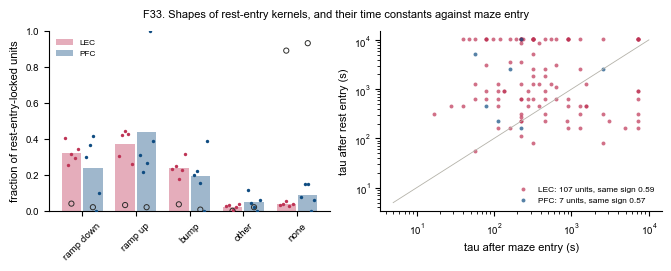

,n,same_sign,tau_rest_median,tau_maze_median
dataset,,,,
LEC,107,0.589,1280.0,320.0
PFC,7,0.571,2560.0,160.0


In [8]:
P.plot_rest_stage2(R, out_path=fig('F33_rest_stage2')); plt.show()
tt = P.table_rest_tau(R)
tt.groupby('dataset').agg(n=('unit', 'size'), same_sign=('same_sign', 'mean'),
                          tau_rest_median=('tau_median_rest', 'median'), tau_maze_median=('tau_median_maze', 'median')).round(3)

## F34. Intrinsic timescales in rest and task, and against the event kernels' time constants

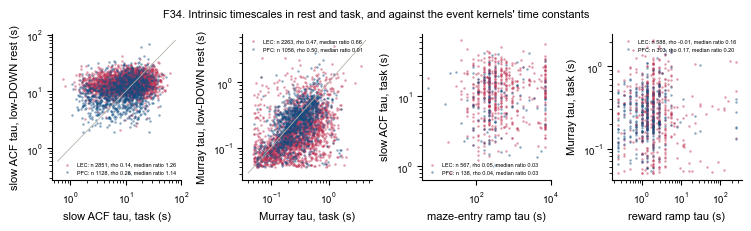

slow_ratio  fast_ratio
dataset mouse                        
LEC     ah08        1.341       0.655
        ah10        0.854       0.560
        ly05        1.391       0.653
        ly06        1.706       0.661
        ly07        1.448       0.811
PFC     ab03        1.433       0.629
        ah03        1.187       1.051
        ah04        1.089       0.891
        ah07        0.944       0.939
        me08        2.719       0.367
        me10        1.534       0.813
        me11        1.009       1.317

In [9]:
P.plot_rest_timescales(R, out_path=fig('F34_rest_timescales')); plt.show()
ts = P.table_rest_timescales(R)
ts.assign(slow_ratio=ts['acf_tau_s_rest_low'] / ts['acf_tau_s_task'],
          fast_ratio=ts['murray_tau_s_rest_low'] / ts['murray_tau_s_task']).groupby(['dataset', 'mouse'])[
    ['slow_ratio', 'fast_ratio']].median().round(3)

## F35. Population drift within 60 s segments of rest and task

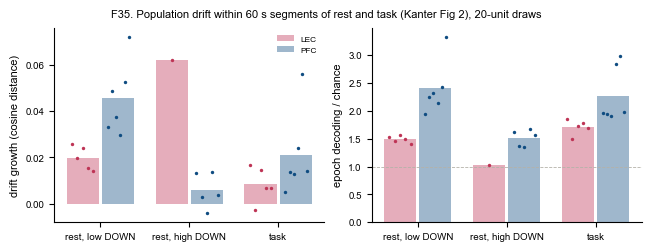

acc_over_chance                    growth                
context             rest_high rest_low   task rest_high rest_low   task
dataset mouse                                                          
LEC     ah08              NaN    1.532  1.851       NaN    0.026  0.017
        ah10              NaN    1.463  1.494       NaN    0.020 -0.003
        ly05              NaN    1.560  1.728       NaN    0.024  0.015
        ly06              NaN    1.486  1.772       NaN    0.016  0.007
        ly07            1.029    1.409  1.698     0.062    0.014  0.007
PFC     ab03            1.620    1.942  1.969     0.013    0.033  0.005
        ah04            1.367    2.248  1.948     0.003    0.048  0.014
        ah07            1.358    2.328  1.902    -0.004    0.038  0.013
        me08            1.681    2.139  2.838     0.013    0.029  0.024
        me10              NaN    2.432  2.978       NaN    0.053  0.056
        me11            1.559    3.324  1.982     0.004    0.072  0.014

In [10]:
P.plot_rest_drift(R, out_path=fig('F35_rest_drift')); plt.show()
P.table_rest_drift(R).pivot_table(index=['dataset', 'mouse'], columns='context', values=['growth', 'acc_over_chance']).round(3)

## F36. The shared state after rest entry, which the design absorbs

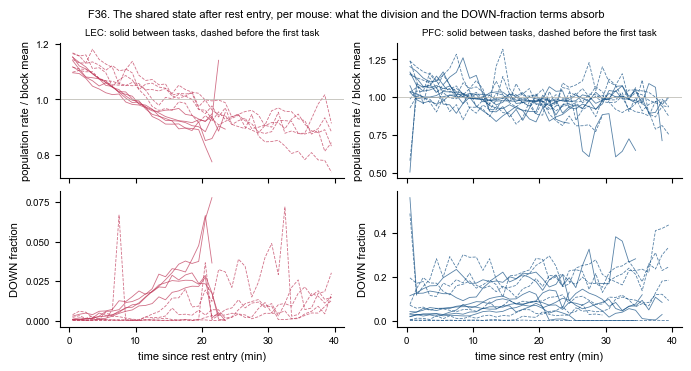

In [11]:
P.plot_rest_course(R, out_path=fig('F36_rest_course')); plt.show()